# ДЗ 2. Агрегация оценок релевантности в Toloka

Взял реальные оценки из [Toloka Aggregation Relevance 5](https://www.kaggle.com/datasets/edsukhodolskaya/toloka-aggregation-relevance-5). Асессор видел запрос и документ и ставил оценку от 1 до 5. В таблице голосов есть ID задания, ID асессора и его ответ. Самих документов и названий градаций в ней нет.

Задача: по нескольким ответам выбрать одну оценку для документа. Сравниваю обычное голосование (MV), голосование с весами асессоров (WMV) и Dawid-Skene (DS). В README Toloka на этом наборе у большинства 89,92% accuracy, у DS 90,72%. Ожидаю результат около 90%. При такой разнице интересно, какие именно решения меняются после учёта асессоров.

## Импорты

In [1]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix
from scipy.special import logsumexp
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split

## Настройки

In [2]:
DATASET = "edsukhodolskaya/toloka-aggregation-relevance-5"
INPUT = Path("/kaggle/input")
SEED = 42
LEVELS = np.arange(1, 6)
CALIBRATION_SHARE = 0.3
PRIOR_VOTES = 10
EM_SMOOTHING = 0.1
MAX_ITER = 1000
TOLERANCE = 1e-6
BOOTSTRAPS = 2000
WMV_GRID = (1, 10, 50)
DS_GRID = (0.03, 0.1, 0.3)
INITIAL_COUNT = 0.1
CV_FOLDS = 5

In [3]:
candidates = sorted(INPUT.rglob("crowd_labels.tsv")) if INPUT.exists() else []
if candidates:
    data_dir = candidates[0].parent
else:
    data_dir = Path(kagglehub.dataset_download(DATASET))

votes = pd.read_csv(
    data_dir / "crowd_labels.tsv", sep="\t", names=["worker", "task", "label"]
)
gold = pd.read_csv(
    data_dir / "golden_labels.tsv", sep="\t", names=["task", "label"]
)
bans = pd.read_csv(data_dir / "bans.tsv", sep="\t", names=["worker", "reason"])
assert not votes.isna().any().any() and not gold.isna().any().any()
assert not votes.duplicated(["worker", "task"]).any()
assert not gold.duplicated().any() and gold.task.isin(votes.task).all()
assert votes.label.isin(LEVELS).all() and gold.label.isin(LEVELS).all()

print(f"{len(votes):,} голосов, {votes.task.nunique():,} заданий, "
      f"{votes.worker.nunique():,} асессора.")
print(f"{gold.task.nunique():,} заданий с эталоном.")
print(f"Блокировки: {len(bans)} записей, "
      f"{bans.worker.nunique()} уникальных асессора.")
display(votes.head(4))

1,091,918 голосов, 363,814 заданий, 1,273 асессора.
33,860 заданий с эталоном.
Блокировки: 90 записей, 84 уникальных асессора.


,worker,task,label
0,w360,t186849,4
1,w43,t174611,5
2,w1040,t198665,3
3,w618,t63171,5


## Данные

В `crowd_labels.tsv` каждая строка соответствует одному голосу. В `golden_labels.tsv` один ID может встретиться дважды: для части документов Toloka принимает две оценки. Обе метки оставил. Поэтому в таблице ниже доли документов по эталонным градациям в сумме больше 100%.

Список блокировок в наборе тоже есть: 90 записей на 84 человека. Когда именно был заблокирован асессор, из данных неизвестно. Для сравнения методов оставил голоса всех участников.

In [4]:
task_id, tasks = pd.factorize(votes.task, sort=True)
worker_id, workers = pd.factorize(votes.worker, sort=True)
label_id = votes.label.to_numpy() - 1
n_tasks, n_workers, k = len(tasks), len(workers), len(LEVELS)
counts = np.bincount(task_id * k + label_id).reshape(n_tasks, k)
overlap = counts.sum(axis=1)
load = np.bincount(worker_id)
allowed = np.zeros((n_tasks, k), dtype=bool)
allowed[tasks.get_indexer(gold.task), gold.label.to_numpy() - 1] = True
n_allowed = allowed.sum(axis=1)
has_gold = n_allowed > 0
unanimous = (counts > 0).sum(axis=1) == 1
ties = (counts == counts.max(axis=1, keepdims=True)).sum(axis=1) > 1

print(f"Полное согласие: {unanimous.mean():.1%}. Ничьи: {ties.mean():.1%}.")
print(f"Несколько допустимых ответов: {(n_allowed > 1).sum():,}.")
display(pd.DataFrame({
    "Показатель": ["Голосов на задание", "Заданий у асессора"],
    "Медиана": [np.median(overlap), np.median(load)],
    "90-й процентиль": [np.quantile(overlap, .9), np.quantile(load, .9)],
    "Максимум": [overlap.max(), load.max()],
}).set_index("Показатель"))
display(pd.DataFrame({
    "Голоса, %": counts.sum(axis=0) / len(votes) * 100,
    "Входит в эталон, %": allowed[has_gold].mean(axis=0) * 100,
}, index=pd.Index(LEVELS, name="Оценка")).round(2))

Полное согласие: 56.1%. Ничьи: 6.2%.
Несколько допустимых ответов: 12,286.


,Медиана,90-й процентиль,Максимум
Показатель,,,
Голосов на задание,3.0,3.0,114
Заданий у асессора,198.0,2444.6,17775


,"Голоса, %","Входит в эталон, %"
Оценка,,
1,5.18,15.83
2,1.34,36.28
3,35.90,36.35
4,18.46,22.06
5,39.12,25.76


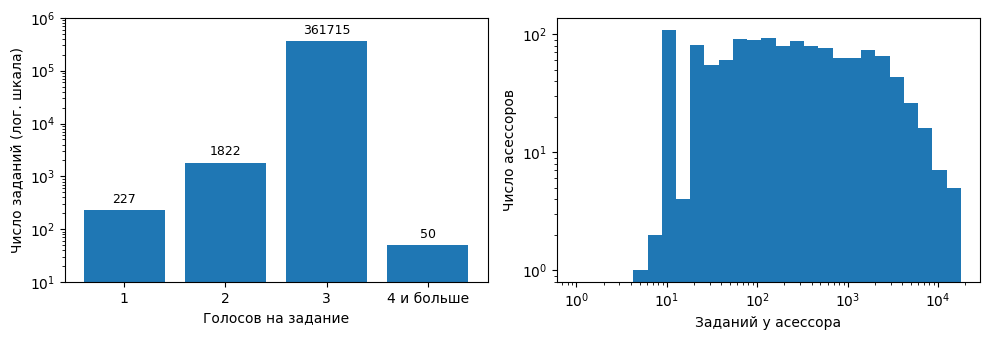

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
bins = np.bincount(np.minimum(overlap, 4), minlength=5)[1:]
bars = axes[0].bar(["1", "2", "3", "4 и больше"], bins)
axes[0].set(yscale="log", ylim=(10, 1_000_000), xlabel="Голосов на задание",
            ylabel="Число заданий (лог. шкала)")
axes[0].bar_label(bars, padding=3, fontsize=9)
axes[1].hist(load, bins=np.geomspace(1, load.max() + 1, 28))
axes[1].set(xscale="log", yscale="log", xlabel="Заданий у асессора",
            ylabel="Число асессоров")
fig.tight_layout()
plt.show()

Почти весь датасет собран по три ответа на документ: 361 715 заданий из 363 814. Всего у 50 заданий больше трёх голосов, максимум 114. Так мог выглядеть сбор с заданным перекрытием: основную массу пар показывали трём людям. Для 50 заданий мог потребоваться отдельный раунд разметки. История назначения заданий в наборе отсутствует. У людей нагрузка совсем другая: медиана 198 заданий, у самого активного асессора их 17 775. Поэтому одному человеку вес можно оценить по десяткам контрольных ответов, а у другого может вообще не оказаться истории на контроле.

На 56,1% документов все ответы совпали. Ещё на 6,2% получилась ничья. При раскладе 3, 3, 4 достаточно одного другого ответа, чтобы большинство сменилось. На таких документах и имеет смысл смотреть, кто какую оценку поставил.

## Разбиение и метрики

Из 33 860 эталонных заданий 30% беру для расчёта весов асессоров, 70% оставляю для проверки. Делю по ID документа с сохранением долей эталонных вариантов. Все ответы на один документ попадают в одну часть.

Accuracy считаю по правилу Toloka. Например, при эталоне {2, 3} прогнозы 2 и 3 получают по одному баллу, прогноз 4 получает ноль. Для macro-F1 оставляю документы с единственной верной оценкой и усредняю F1 по градациям, которые действительно встретились в этом срезе.

In [6]:
gold_ids = np.flatnonzero(has_gold)
patterns = allowed[gold_ids] @ (2 ** np.arange(k))
pattern_sizes = pd.Series(patterns).value_counts()
strata = np.where(pd.Series(patterns).map(pattern_sizes) >= 5, patterns, -1)
cal, test = train_test_split(
    gold_ids, train_size=CALIBRATION_SHARE, stratify=strata, random_state=SEED
)
single = test[n_allowed[test] == 1]
multi = test[n_allowed[test] > 1]
assert not np.intersect1d(cal, test).size
print(f"Калибровка: {len(cal):,}. Тест: {len(test):,}. "
      f"Один эталон: {len(single):,}, несколько: {len(multi):,}.")

Калибровка: 10,158. Тест: 23,702. Один эталон: 15,102, несколько: 8,600.


## Какие задания попали в контроль

Эталон есть у 33 860 из 363 814 заданий. Сравниваю их с оставшимися по признакам, которые видны с обеих сторон: числу голосов, согласию людей и частотам выставленных оценок. У единственного голоса согласие получается автоматически, поэтому отдельно считаю ту же долю для документов ровно с тремя ответами. В последней таблице каждая строка относится к оценке отдельного асессора.

In [7]:
cohorts = {
    "Все": np.arange(n_tasks), "С эталоном": gold_ids,
    "Без эталона": np.flatnonzero(~has_gold), "Калибровка": cal, "Тест": test,
}
cohort_rows = []
for name, ids in cohorts.items():
    three = ids[overlap[ids] == 3]
    cohort_rows.append({
        "Часть": name, "Заданий": len(ids),
        "Ровно три голоса, %": 100 * (overlap[ids] == 3).mean(),
        "Единогласно, %": 100 * unanimous[ids].mean(),
        "Ничьи, %": 100 * ties[ids].mean(),
        "Единогласно при трёх, %": 100 * unanimous[three].mean(),
    })
display(pd.DataFrame(cohort_rows).set_index("Часть").round(2))
vote_shares = pd.DataFrame({
    name: counts[ids].sum(axis=0) / overlap[ids].sum() * 100
    for name, ids in cohorts.items()
}, index=pd.Index(LEVELS, name="Ответ асессора"))
display(vote_shares.round(2))
top_count = int(np.ceil(n_workers * .1))
top_share = np.sort(load)[-top_count:].sum() / len(votes)
print(f"Самые активные {top_count} асессоров дали {top_share:.1%} голосов.")

,Заданий,"Ровно три голоса, %","Единогласно, %","Ничьи, %","Единогласно при трёх, %"
Часть,,,,,
Все,363814,99.42,56.08,6.16,55.99
С эталоном,33860,99.25,67.87,3.81,67.92
Без эталона,329954,99.44,54.87,6.40,54.77
Калибровка,10158,99.35,68.04,3.60,68.06
Тест,23702,99.21,67.79,3.90,67.86


,Все,С эталоном,Без эталона,Калибровка,Тест
Ответ асессора,,,,,
1,5.18,14.52,4.19,14.38,14.59
2,1.34,1.84,1.29,1.77,1.87
3,35.90,35.58,35.93,36.27,35.28
4,18.46,21.35,18.16,21.03,21.48
5,39.12,26.71,40.42,26.55,26.78


Самые активные 128 асессоров дали 56.1% голосов.


Калибровка и тест похожи: доля единогласных решений в обеих частях около 68%. Главная разница появляется раньше, когда из всего набора выделяется контроль. При одинаковых трёх голосах асессоры сошлись на 67,92% контрольных документов и только на 54,77% остальных. Значит, дело не в редких заданиях, на которые пригласили больше людей. Меняется и состав ответов: единицы на контроле встречаются в 14,52% голосов против 4,19% вне контроля, а пятёрки в 26,71% против 40,42%.

По таким признакам контроль смещён в сторону документов, где людям проще договориться. Возможное объяснение: для контроля удобнее выбрать документ, которому легче задать эталон. Как именно Toloka отбирала эти документы, в файлах не указано. Кроме того, у асессоров сильно различается нагрузка: десятая часть самых активных участников дала 56,1% голосов. В оценке случайного голоса их решения будут встречаться чаще, чем при выборе случайного человека.

## Голосование

В **Majority Vote** каждый голос даёт своей оценке один балл. Если две или три оценки делят первое место, выбираю меньшую. Это правило понадобится при разборе ничьих.

В **Weighted Majority Vote** голос даёт столько баллов, сколько весит асессор. Вес считаю по его попаданиям в эталон на калибровке. Чтобы участник с одним верным ответом сразу не получил вес 1, добавляю к его истории десять условных ответов со средней точностью по калибровке. Для участника без истории вес получается равен этой средней.

In [8]:
def vote_with_weights(
    tasks_idx: np.ndarray, people: np.ndarray, answers: np.ndarray,
    reliability: np.ndarray, shape: tuple[int, int],
) -> np.ndarray:
    total = np.bincount(
        tasks_idx * shape[1] + answers, weights=reliability[people],
        minlength=shape[0] * shape[1],
    )
    return total.reshape(shape).argmax(axis=1)


on_cal = np.isin(task_id, cal)
n_cal = np.bincount(worker_id[on_cal], minlength=n_workers)
hits = allowed[task_id[on_cal], label_id[on_cal]]
n_hits = np.bincount(worker_id[on_cal], weights=hits, minlength=n_workers)
weights = (n_hits + PRIOR_VOTES * hits.mean()) / (n_cal + PRIOR_VOTES)
pred = {
    "MV": counts.argmax(axis=1),
    "WMV": vote_with_weights(
        task_id, worker_id, label_id, weights, counts.shape
    ),
}
print(f"Средняя точность голоса на калибровке: {hits.mean():.2%}. "
      f"Асессоров без калибровочных голосов: {(n_cal == 0).sum()}.")
print("10-й, 50-й и 90-й процентили веса:",
      np.round(np.quantile(weights, [.1, .5, .9]), 3))

Средняя точность голоса на калибровке: 84.35%. Асессоров без калибровочных голосов: 133.
10-й, 50-й и 90-й процентили веса: [0.726 0.844 0.897]


In [9]:
example_task = "t249868"
example = votes.loc[votes.task == example_task, ["worker", "label"]].copy()
example_workers = workers.get_indexer(example.worker)
example["Верных на калибровке"] = n_hits[example_workers].astype(int)
example["Всего на калибровке"] = n_cal[example_workers]
example["Вес"] = weights[example_workers].round(3)
display(example.sort_values("label").set_index("worker"))

,label,Верных на калибровке,Всего на калибровке,Вес
worker,,,,
w365,1,3,7,0.673
w959,3,42,49,0.855
w31,5,145,194,0.752


На `t249868` три разных оценки. За единицу проголосовал w365, у него 3 верных ответа из 7 на калибровке. За тройку проголосовал w959 с 42 попаданиями из 49. У него самый большой вес (0,855), поэтому WMV ставит 3. Эталон у документа 1. Здесь большинство попало в ответ благодаря правилу ничьей, а надёжный по прошлым заданиям асессор ошибся.

Вес 10 даёт истории человека и общему среднему одинаковый вклад после десяти контрольных ответов. При одном ответе доля собственной истории всего 1/11, при ста уже 100/110. Чтобы проверить, насколько вывод зависит от этой настройки, разбил калибровочные задания на пять частей. Каждый раз пересчитываю веса на четырёх частях и проверяю на пятой. Так каждый контрольный документ оценивается один раз без своего эталона в весах.

In [10]:
folds = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
cv_hits = {strength: 0 for strength in WMV_GRID}
for train_pos, val_pos in folds.split(cal, allowed[cal] @ (2 ** np.arange(k))):
    learn = np.isin(task_id, cal[train_pos])
    val_ids = np.sort(cal[val_pos])
    evaluate = np.isin(task_id, val_ids)
    seen = np.bincount(worker_id[learn], minlength=n_workers)
    right = allowed[task_id[learn], label_id[learn]]
    good = np.bincount(worker_id[learn], weights=right, minlength=n_workers)
    for strength in WMV_GRID:
        skill = (good + strength * right.mean()) / (seen + strength)
        choice = vote_with_weights(
            np.searchsorted(val_ids, task_id[evaluate]), worker_id[evaluate],
            label_id[evaluate], skill, (len(val_ids), k),
        )
        cv_hits[strength] += int(allowed[val_ids, choice].sum())
cv_table = pd.Series(cv_hits, name="Верно").rename_axis("Условных ответов")
display(cv_table.to_frame().assign(
    **{"Accuracy вне фолда, %": (100 * cv_table / len(cal)).round(3)}
))

,Верно,"Accuracy вне фолда, %"
Условных ответов,,
1,9161,90.185
10,9161,90.185
50,9162,90.195


При сглаживании 1 и 10 WMV правильно решил по 9161 контрольному заданию из 10 158, при 50 получилось 9162. В этой проверке разница между крайними вариантами всего один документ. Оставил исходное значение 10: оно заметно сглаживает вес новичка и уже мало влияет на человека с сотней контрольных ответов. Оснований считать именно 10 оптимумом по accuracy здесь нет.

## Dawid-Skene

У WMV вес один на все пять оценок. Если человек хорошо узнаёт документы с оценкой 5, но часто ставит 3 вместо 4, его голос в обоих случаях весит одинаково. В DS для каждого человека оценивается матрица 5 × 5. Например, элемент в строке 4 и столбце 3 отвечает за вероятность получить от него тройку, когда правильная оценка 4.

Начальные вероятности классов беру из голосов за документ. Дальше чередуются два шага: по текущим вероятностям считаю матрицы асессоров, затем по их матрицам и ответам обновляю вероятности документа. Ко всем ячейкам матрицы добавляю 0,1, иначе одно ненаблюдавшееся сочетание может обнулить вероятность класса. Модель использует все голоса. Эталонные метки в эти вычисления не входят.

In [11]:
def fit_dawid_skene(
    task: np.ndarray, worker: np.ndarray, label: np.ndarray,
    vote_counts: np.ndarray, smoothing: float, max_iter: int, tolerance: float,
) -> tuple[np.ndarray, list[float]]:
    n_items, n_classes = vote_counts.shape
    n_people = int(worker.max()) + 1
    posterior = (vote_counts + INITIAL_COUNT).astype(float)
    posterior /= posterior.sum(axis=1, keepdims=True)
    history = []
    # Each sparse matrix links workers and tasks for one observed answer.
    links = [
        csr_matrix(
            (np.ones(mask.sum()), (task[mask], worker[mask])),
            shape=(n_items, n_people),
        )
        for mask in (label == value for value in range(n_classes))
    ]
    for _ in range(max_iter):
        prior = posterior.mean(axis=0)
        confusion = np.stack([m.T @ posterior for m in links], axis=2)
        confusion += smoothing
        confusion /= confusion.sum(axis=2, keepdims=True)
        log_prob = np.broadcast_to(np.log(prior), posterior.shape).copy()
        for value, link in enumerate(links):
            log_prob += link @ np.log(confusion[:, :, value])
        updated = np.exp(log_prob - logsumexp(log_prob, axis=1, keepdims=True))
        change = float(np.abs(updated - posterior).mean())
        history.append(change)
        posterior = updated
        if change < tolerance:
            break
    return posterior.argmax(axis=1), history


pred["DS"], changes = fit_dawid_skene(
    task_id, worker_id, label_id, counts, EM_SMOOTHING, MAX_ITER, TOLERANCE
)
print(f"Итераций: {len(changes)}. Среднее изменение вероятности: "
      f"{changes[-1]:.2e}. Порог: {TOLERANCE:.0e}.")

Итераций: 315. Среднее изменение вероятности: 9.93e-07. Порог: 1e-06.


На первом прогоне я ограничил DS 120 итерациями. К этому моменту среднее изменение вероятности было $1{,}61 \cdot 10^{-5}$ при пороге $10^{-6}$. Поднял лимит до 1000. Условие остановки выполнилось на 315-й итерации.

Матрица каждого асессора считается постоянной для всех его заданий. Значит, одна и та же строка описывает и простой документ, и пограничный. Ещё DS перемножает вероятности ответов людей, как если бы при известном классе они отвечали независимо. Даже если люди работали по отдельности, одна двусмысленная формулировка запроса может склонить нескольких из них к одной и той же ошибке. Тогда совпавшие голоса дадут модели больше уверенности, чем заслуживают.

Для матрицы 5 × 5 добавка 0,1 означает полголоса на строку. Пустая строка получает равные вероятности, а у человека с десятками наблюдений этой градации добавка почти ничего не весит. Проверил также 0,03 и 0,3 при одинаковом старте EM: к исходным счётчикам голосов везде прибавил 0,1. Между прогонами меняю только добавку в матрице асессора. Во всех трёх запусках использую все голоса, попадания в эталон сравниваю только на калибровочной части. Основной вариант оставляю тем же, что в первом эксперименте.

In [12]:
ds_checks = []
for alpha in DS_GRID:
    if alpha == EM_SMOOTHING:
        labels, path = pred["DS"], changes
    else:
        labels, path = fit_dawid_skene(
            task_id, worker_id, label_id, counts, alpha, MAX_ITER, TOLERANCE
        )
    ds_checks.append({
        "Добавка в ячейку": alpha, "Итераций": len(path),
        "Порог достигнут": path[-1] < TOLERANCE,
        "Accuracy на контроле, %": 100 * allowed[cal, labels[cal]].mean(),
        "Сменили ответ к базе, %": 100 * np.mean(
            labels[cal] != pred["DS"][cal]
        ),
    })
display(pd.DataFrame(ds_checks).set_index("Добавка в ячейку").round(3))

,Итераций,Порог достигнут,"Accuracy на контроле, %","Сменили ответ к базе, %"
Добавка в ячейку,,,,
0.03,404,True,90.648,0.364
0.10,315,True,90.648,0.000
0.30,196,True,90.736,0.847


Все три запуска сошлись. При 0,03 и 0,1 получилось по 90,65% на калибровке. При 0,3 результат чуть выше: 90,74%, разница в девять документов из 10 158. По сравнению с базовым значением сменилось меньше 1% прогнозов при каждой замене. Для основного сравнения оставил 0,1: это слабая поправка к редким сочетаниям, а прирост от более сильного сглаживания на контроле мал. На этом наборе выбор конкретного значения в проверенном диапазоне мало влияет на общую accuracy.

## Результаты

У всех методов одни и те же 23 702 тестовых задания. Кроме accuracy, считаю, сколько ошибок большинства исправил каждый метод и сколько верных решений потерял. Для разницы с MV беру парный bootstrap по заданиям: 2000 повторов, веса и матрицы асессоров фиксированы.

In [13]:
def paired_interval(difference: np.ndarray) -> tuple[float, float]:
    frequencies = np.bincount(difference + 1, minlength=3) / difference.size
    rng = np.random.default_rng(SEED)
    samples = rng.multinomial(difference.size, frequencies, size=BOOTSTRAPS)
    gains = (samples[:, 2] - samples[:, 0]) * 100 / difference.size
    low, high = np.quantile(gains, [.025, .975])
    return float(low), float(high)


correct = {name: allowed[test, labels[test]] for name, labels in pred.items()}
single_truth = allowed[single].argmax(axis=1)
supported = np.unique(single_truth)
rows = []
for name, labels in pred.items():
    delta = correct[name].astype(int) - correct["MV"].astype(int)
    low, high = paired_interval(delta)
    rows.append({
        "Метод": name, "Accuracy, %": 100 * correct[name].mean(),
        "Один эталон, %": 100 * allowed[single, labels[single]].mean(),
        "Несколько, %": 100 * allowed[multi, labels[multi]].mean(),
        "Macro-F1 (один)": f1_score(
            single_truth, labels[single], labels=supported,
            average="macro", zero_division=0,
        ),
        "Δ к MV, п.п.": 100 * delta.mean(),
        "95% ДИ, п.п.": f"[{low:.2f}, {high:.2f}]",
        "Исправил MV": (delta == 1).sum(), "Испортил MV": (delta == -1).sum(),
    })
summary = pd.DataFrame(rows).set_index("Метод")
summary.to_csv("aggregation_metrics.csv")
display(summary.round(3).T)

Метод,MV,WMV,DS
"Accuracy, %",90.25,90.482,90.786
"Один эталон, %",88.617,89.664,90.611
"Несколько, %",93.116,91.919,91.093
Macro-F1 (один),0.698,0.702,0.706
"Δ к MV, п.п.",0.0,0.232,0.536
"95% ДИ, п.п.","[0.00, 0.00]","[0.06, 0.40]","[0.30, 0.77]"
Исправил MV,0,236,479
Испортил MV,0,181,352


In [14]:
groups = {
    "Единогласно": unanimous[test],
    "Лидер с перевесом": ~unanimous[test] & ~ties[test],
    "Ничья по голосам": ties[test],
}
by_agreement = pd.DataFrame([
    {"Голоса": title, "Заданий": mask.sum(),
     **{name: 100 * hit[mask].mean() for name, hit in correct.items()}}
    for title, mask in groups.items()
]).set_index("Голоса")
display(by_agreement.round(2))

,Заданий,MV,WMV,DS
Голоса,,,,
Единогласно,16068,98.09,98.09,98.06
Лидер с перевесом,6710,77.54,77.54,78.60
Ничья по голосам,924,46.21,52.16,52.81


В тесте много единогласных документов, а на них почти все ответы верные. Насколько это поднимает общую цифру? Оставлю accuracy каждой из трёх групп такой, как на тесте, и заменю только доли групп на те, что встретились у документов без эталона.

In [15]:
mix_weights = pd.Series({
    "Единогласно": unanimous[~has_gold].mean(),
    "Лидер с перевесом": (~unanimous[~has_gold] & ~ties[~has_gold]).mean(),
    "Ничья по голосам": ties[~has_gold].mean(),
})
adjusted = by_agreement[list(pred)].mul(mix_weights, axis=0).sum()
display(pd.DataFrame({
    "Тест, %": summary["Accuracy, %"],
    "При долях групп вне контроля, %": adjusted,
    "Изменение, п.п.": adjusted - summary["Accuracy, %"],
}).round(2))

,"Тест, %","При долях групп вне контроля, %","Изменение, п.п."
MV,90.25,86.81,-3.44
WMV,90.48,87.19,-3.29
DS,90.79,87.63,-3.16


Если сохранить качество внутри групп и взять их доли вне контроля, у MV получается 86,81% вместо 90,25%, у DS 87,63% вместо 90,79%. Одной замены пропорций хватает для сдвига больше чем на три пункта. Это расчёт при условии, что, например, все ничьи одинаково трудны в обеих частях. Проверить это условие без эталонов нельзя. Поэтому фактическую accuracy по всем 363 814 документам из такой поправки получить не удастся.

В среднем у DS 90,79% против 90,25% у MV. DS исправил 479 ошибок большинства, но сам ошибся на 352 документах, которые большинство оценило верно. Чистый выигрыш 127 заданий, или 0,54 п.п. Парный 95% интервал для разницы получился от 0,30 до 0,77 п.п.

- При единственном эталоне у DS на 301 верный ответ больше, чем у MV. На заданиях с двумя эталонами у него на 174 верных ответа меньше. Отсюда и небольшая общая прибавка.
- У WMV прибавка к большинству составила 55 заданий. Именно на 924 ничьих WMV набрал на 55 верных ответов больше. Когда у одной оценки уже был перевес, итоговая accuracy у MV и WMV совпала до сотых (77,54%).
- Самая многочисленная группа в тесте, 16 068 заданий, размечена единогласно. На ней все методы дают около 98%. Поэтому разница в несколько пунктов на спорных документах даёт лишь доли пункта в общей таблице.

Для прямого сравнения DS с WMV считаю только те случаи, где один метод попал в эталон, а другой ошибся. В bootstrap каждый документ попадает в выборку сразу с обоими прогнозами.

In [16]:
comparison = []
for title, mask in {
    "Весь тест": np.ones(len(test), dtype=bool),
    "Один эталон": n_allowed[test] == 1,
    "Эталон {2, 3}": n_allowed[test] > 1,
}.items():
    delta = correct["DS"][mask].astype(int) - correct["WMV"][mask].astype(int)
    low, high = paired_interval(delta)
    comparison.append({
        "Тест": title, "Заданий": len(delta),
        "Верен только DS": (delta == 1).sum(),
        "Верно только WMV": (delta == -1).sum(),
        "DS минус WMV, п.п.": 100 * delta.mean(),
        "95% ДИ, п.п.": f"[{low:.2f}, {high:.2f}]",
    })
display(pd.DataFrame(comparison).set_index("Тест").round(3))

,Заданий,Верен только DS,Верно только WMV,"DS минус WMV, п.п.","95% ДИ, п.п."
Тест,,,,,
Весь тест,23702,402,330,0.304,"[0.08, 0.52]"
Один эталон,15102,323,180,0.947,"[0.66, 1.22]"
"Эталон {2, 3}",8600,79,150,-0.826,"[-1.17, -0.50]"


Из 23 702 тестовых заданий на 402 попал в эталон только DS, на 330 только WMV. Разница 72 задания, или 0,30 п.п. Парный 95% интервал от 0,08 до 0,52 п.п. На однозначных заданиях преимущество DS составило 0,95 п.п., на документах с эталоном {2, 3} лучше WMV на 0,83 п.п. Знак разницы зависит от того, какую часть заданий сравниваем.

Интервал получен повторным выбором тестовых документов. Асессоры, их веса и само разбиение при этом остаются теми же. Такая проверка учитывает разброс по документам на данном тесте. Для переноса на новую группу асессоров или другой отбор контроля понадобилась бы отдельная проверка.

## Дополнительное задание. Какие градации путают асессоры?

Беру два голоса за один документ и смотрю, какие две оценки в них встретились. У документа с голосами 3, 3, 4 есть три пары людей: одна пара согласна, две расходятся между 3 и 4. Сначала считаю доли пар внутри каждого документа, потом усредняю по документам с двумя и более голосами. Иначе задание со 114 ответами дало бы 6441 пару и перевесило бы две тысячи обычных заданий.

In [17]:
pair_total = overlap * (overlap - 1) / 2
eligible = pair_total > 0
pair_rows = []
for left in range(k):
    for right in range(left + 1, k):
        pair_count = counts[eligible, left] * counts[eligible, right]
        share = np.mean(pair_count / pair_total[eligible])
        pair_rows.append((LEVELS[left], LEVELS[right], share))
pairs = pd.DataFrame(pair_rows, columns=["Оценка A", "Оценка B", "Частота"])
disagreement = pairs["Частота"].sum()
pairs["Среди расхождений, %"] = 100 * pairs["Частота"] / disagreement
print(f"Два случайных асессора расходятся с вероятностью {disagreement:.1%}.")
display(pairs.nlargest(5, "Частота").drop(columns="Частота").round(2))

Два случайных асессора расходятся с вероятностью 31.4%.


,Оценка A,Оценка B,"Среди расхождений, %"
9,4,5,31.46
7,3,4,28.37
8,3,5,26.21
4,2,3,5.02
1,1,3,2.65


In [18]:
item_fractions = counts[eligible] / overlap[eligible, None]
marginal = item_fractions.mean(axis=0)
chance_agreement = marginal @ marginal
print(f"Согласие пары на одном документе: {1 - disagreement:.1%}.")
print(f"Независимые ответы с теми же частотами: {chance_agreement:.1%}.")

Согласие пары на одном документе: 68.6%.
Независимые ответы с теми же частотами: 31.9%.


Если взять случайный документ с двумя или более голосами и выбрать пару асессоров, вероятность разных ответов составляет 31,4%. Самая частая пара среди расхождений: 4 и 5 (31,46%). Интереснее третья строка. Пара 3 и 5 (26,21%) встречается почти так же часто, как соседние 3 и 4 (28,37%). Значит, заметная часть разногласий приходится сразу на две ступени шкалы. При этом сами 3 и 5 очень частые: на них приходится 75% всех голосов.

Часть совпадений могла бы получиться просто потому, что людям часто встречаются тройки и пятёрки. Если сохранить частоты оценок при том же выборе документа, но независимо вытянуть два ответа из общего распределения, вероятность совпадения составит 31,9%. У людей, видевших один и тот же документ, она 68,6%. Похоже, в голосах есть общий сигнал о содержании пары «запрос, документ». Какую его часть дают свойства документа, а какую общая инструкция, по одним оценкам разделить нельзя.

По двум разным ответам ещё неизвестно, какой из них верный. Для направления ошибки беру тестовые документы с одной эталонной оценкой. На первой матрице каждый голос считается отдельно, на остальных один документ даёт один прогноз. Проценты нормированы по строке: в строке 4 видно, куда ушли оценки документов с эталоном 4.

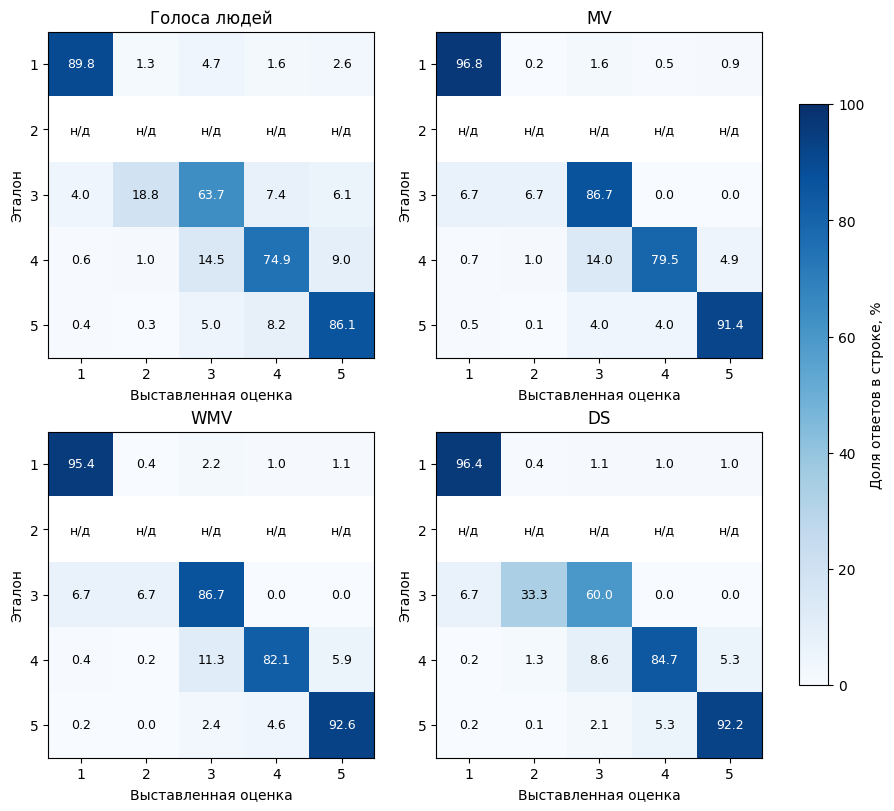

In [19]:
on_single = np.isin(task_id, single)
human_truth = allowed[task_id[on_single]].argmax(axis=1)
matrices = {"Голоса людей": confusion_matrix(
    human_truth, label_id[on_single], labels=np.arange(k)
)}
for name, labels in pred.items():
    matrices[name] = confusion_matrix(
        single_truth, labels[single], labels=np.arange(k)
    )

fig, axes = plt.subplots(2, 2, figsize=(9, 8), layout="constrained")
for ax, (name, matrix) in zip(axes.flat, matrices.items()):
    support = matrix.sum(axis=1, keepdims=True)
    percent = np.divide(
        100.0 * matrix, support, where=support > 0,
        out=np.full(matrix.shape, np.nan),
    )
    image = ax.imshow(percent, cmap="Blues", vmin=0, vmax=100)
    for row, col in np.ndindex(percent.shape):
        value = percent[row, col]
        text = f"{value:.1f}" if np.isfinite(value) else "н/д"
        ax.text(col, row, text, ha="center", va="center",
                color="white" if value > 55 else "black", fontsize=9)
    ax.set(xticks=np.arange(k), yticks=np.arange(k), xticklabels=LEVELS,
           yticklabels=LEVELS, xlabel="Выставленная оценка",
           ylabel="Эталон", title=name)
fig.colorbar(image, ax=axes, shrink=.8, label="Доля ответов в строке, %")
plt.show()

In [20]:
def error_profile(matrix: np.ndarray) -> pd.DataFrame:
    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    top = off_diagonal.argmax(axis=1)
    total = matrix.sum(axis=1)
    present = np.flatnonzero(total)
    return pd.DataFrame({
        "Эталон": LEVELS[present], "Число": total[present],
        "Ошибки, %": 100 * off_diagonal[present].sum(axis=1) / total[present],
        "Чаще путают с": LEVELS[top[present]],
        "В эту градацию, %": 100 * off_diagonal[present, top[present]]
        / total[present],
    }).set_index("Эталон")


profiles = {name: error_profile(m) for name, m in matrices.items()}
display(profiles["Голоса людей"].round(1))
print("Число тестовых заданий по одиночному эталону:",
      dict(zip(LEVELS.tolist(), matrices["MV"].sum(axis=1).tolist())))
display(pd.DataFrame({
    name: profile["Ошибки, %"] for name, profile in profiles.items()
}).round(1))
for name, matrix in matrices.items():
    distance = np.abs(LEVELS[:, None] - LEVELS)
    near = matrix[distance == 1].sum() / matrix[distance > 0].sum()
    print(f"{name}: соседние градации составляют {near:.1%} всех ошибок.")

,Число,"Ошибки, %",Чаще путают с,"В эту градацию, %"
Эталон,,,,
1,11458,10.2,3,4.7
3,719,36.3,2,18.8
4,15891,25.1,3,14.5
5,19156,13.9,4,8.2


Число тестовых заданий по одиночному эталону: {1: 3751, 2: 0, 3: 15, 4: 5229, 5: 6107}


,Голоса людей,MV,WMV,DS
Эталон,,,,
1,10.2,3.2,4.6,3.6
3,36.3,13.3,13.3,40.0
4,25.1,20.5,17.9,15.3
5,13.9,8.6,7.4,7.8


Голоса людей: соседние градации составляют 69.7% всех ошибок.
MV: соседние градации составляют 71.9% всех ошибок.
WMV: соседние градации составляют 77.0% всех ошибок.
DS: соседние градации составляют 75.5% всех ошибок.


Больше всего DS помог четвёркам. У людей 14,5% голосов за документы с эталоном 4 ушли в тройку. Даже у большинства таких прогнозов 14,0%, у DS уже 8,6%. Всего по этому классу доля ошибок снизилась с 20,5% до 15,3% на 5 229 документах. На пятёрках лучший результат у взвешенного голосования (7,4% ошибок), на единицах у обычного большинства (3,2%).

Строку с эталоном 3 легко переоценить: у DS там 40% ошибок. В этой строке всего **15 документов**. Люди оставили на них 719 голосов, но у метода всё равно только 15 прогнозов. DS ошибся на шести, MV на двух. У оценки 2 своей строки с наблюдениями вообще нет: каждый раз, когда в эталоне встречается двойка, Toloka также принимает тройку.

**Документы с эталоном {2, 3}.** Таких в тесте 8 600. Здесь считать путаницу между двойкой и тройкой ошибкой было бы странно: оба ответа подходят по условию разметки. В таблице ошибка означает, что метод поставил 1, 4 или 5.

Обычный DS предполагает у каждого документа ровно один скрытый класс. На шаге EM голоса за него усиливают соответствующую строку матрицы асессора. На границе 2 и 3 два человека могут поставить разные оценки и оба попасть в эталон. Модель такой вариант явно не описывает: ей всё равно приходится распределять вероятность между взаимоисключающими классами. Даже если она отдаст почти всю вероятность двойке, тройка может быть столь же допустимой по правилам Toloka. Поэтому максимум вероятности DS здесь нельзя читать как вероятность того, что остальные ответы ошибочны.

Сам по себе переход между 2 и 3 не меняет нашу accuracy. Потеря возникает только при уходе за пределы пары. В таблице ниже как раз посчитана доля таких решений. У исходных текстов нет открытой разметки причин, поэтому по этим цифрам нельзя установить, вызвана ли конкретная ошибка двусмысленностью документа, привычкой человека или общим толкованием инструкции.

In [21]:
on_multi = np.isin(task_id, multi)
print("Голоса людей вне допустимого множества: "
      f"{1 - allowed[task_id[on_multi], label_id[on_multi]].mean():.2%}.")
allowed_text = {
    item: ", ".join(map(str, LEVELS[allowed[item]])) for item in multi
}
multi_results = pd.DataFrame({
    "Допустимы": [allowed_text[item] for item in multi],
    **{name: ~allowed[multi, labels[multi]] for name, labels in pred.items()},
})
grouped = multi_results.groupby("Допустимы")
pair_errors = grouped[list(pred)].mean().mul(100)
pair_errors.insert(0, "Заданий", grouped.size())
display(pair_errors.sort_values("Заданий", ascending=False).head(6).round(2))

examples = []
for title, mask in {
    "Исправил": correct["DS"] & ~correct["MV"],
    "Ошибся": ~correct["DS"] & correct["MV"],
}.items():
    for item in test[mask][:2]:
        examples.append({
            "DS против MV": title, "Задание": tasks[item],
            "Голоса (1..5)": counts[item].tolist(),
            "Допустимы": LEVELS[allowed[item]].tolist(),
            **{name: LEVELS[labels[item]] for name, labels in pred.items()},
        })
display(pd.DataFrame(examples).set_index("Задание"))

Голоса людей вне допустимого множества: 13.16%.


,Заданий,MV,WMV,DS
Допустимы,,,,
"2, 3",8600,6.88,8.08,8.91


,DS против MV,Голоса (1..5),Допустимы,MV,WMV,DS
Задание,,,,,,
t333682,Исправил,"[0, 0, 0, 1, 2]",[4],5,5,4
t314474,Исправил,"[0, 0, 2, 1, 0]",[4],3,3,4
t249868,Ошибся,"[1, 0, 1, 0, 1]",[1],1,3,3
t303678,Ошибся,"[0, 0, 2, 1, 0]","[2, 3]",3,3,4


У двух документов в таблице одинаковые голоса: две тройки и одна четвёрка. Для `t314474` эталон 4. DS выбрал четвёрку и исправил большинство. Для `t303678` эталон {2, 3}. DS снова выбрал четвёрку и на этот раз потерял верный ответ. Для самого голосования эти документы выглядят одинаково. У DS решение зависит ещё и от того, кто выставил каждую оценку.

## Выводы

При правиле Toloka на этом тесте DS дал 90,79%, WMV 90,48%, обычное большинство 90,25%. У DS небольшой перевес над WMV: 72 дополнительных верных решения. Для документов с единственным эталоном я бы взял DS, особенно если важны ошибки на четвёрках. Если в разметке много документов на границе 2 и 3, вывод меняется. На этой части теста чаще всего попадало в эталон обычное большинство (93,12%), затем WMV (91,92%) и DS (91,09%).

Переносить этот порядок и эти проценты на всю выдачу я бы пока не стал. Среди заданий без эталона больше разногласий, а у DS и WMV как раз расходятся решения на спорных документах. Для проверки я бы случайно отобрал документы вне текущего контроля, сохранил доли единогласных заданий и ничьих и отдал их на независимую проверку с возможностью указать несколько допустимых оценок.